# Phase 4 (Run): Derivatives Portfolio Risk (Options & Interest-Rate Swap), Stressed VaR & Scenario Stress Testing
**Multi-Asset Macro Trading Desk ($10,000,000 Notional | C++17 BSM & Full Revaluation Monte Carlo Kernel)**

### Executive Objective
This notebook extends the risk engine to non-linear equity options (`SPY` Protective Put & ATM Delta-Neutral Straddle) and a **5-Year USD Interest-Rate Swap ($5,000,000 Notional)**:
1. **BSM Pricing, Implied Volatility Inversion & Analytical Greeks ($\Delta, \Gamma, \mathcal{V}, \Theta$)**.
2. **Comparing Linear Delta-Normal / DV01 vs. Quadratic Delta-Gamma-Vega / Convexity vs. Full Revaluation Monte Carlo ($M=20,000$)** across options and the 5-Year Interest-Rate Swap, showing where Taylor approximations break down.
3. **Basel 2.5 Stressed VaR ($\text{sVaR}_{0.99}$) vs. Normal-Period VaR:** Comparing tranquil 2017 calibration against the 2020 COVID-19 and 2022 Rate-Hike stress windows.
4. **Historical Crisis Replay & $5 \times 5$ Spot–Volatility Stress Grid**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("/Users/mukundankit/Documents/Finance/market_risk_modelling")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, prepare_and_save_processed_data
from src.derivatives_stress import (
    generate_spy_option_chain_snapshot,
    compare_derivative_var_approaches,
    evaluate_swap_approximation_breakdown,
    compute_stressed_var_comparison,
    run_historical_crisis_replay,
    build_2d_stress_vulnerability_grid,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (13.5, 5.2)
plt.rcParams["figure.dpi"] = 120

cfg = load_config()
bundle = prepare_and_save_processed_data(cfg)
arith_returns = bundle["arith_returns"]
vix_df = bundle["vix"]
weights = cfg["portfolio"]["weights"]
notional_usd = float(cfg["portfolio"]["notional_usd"])

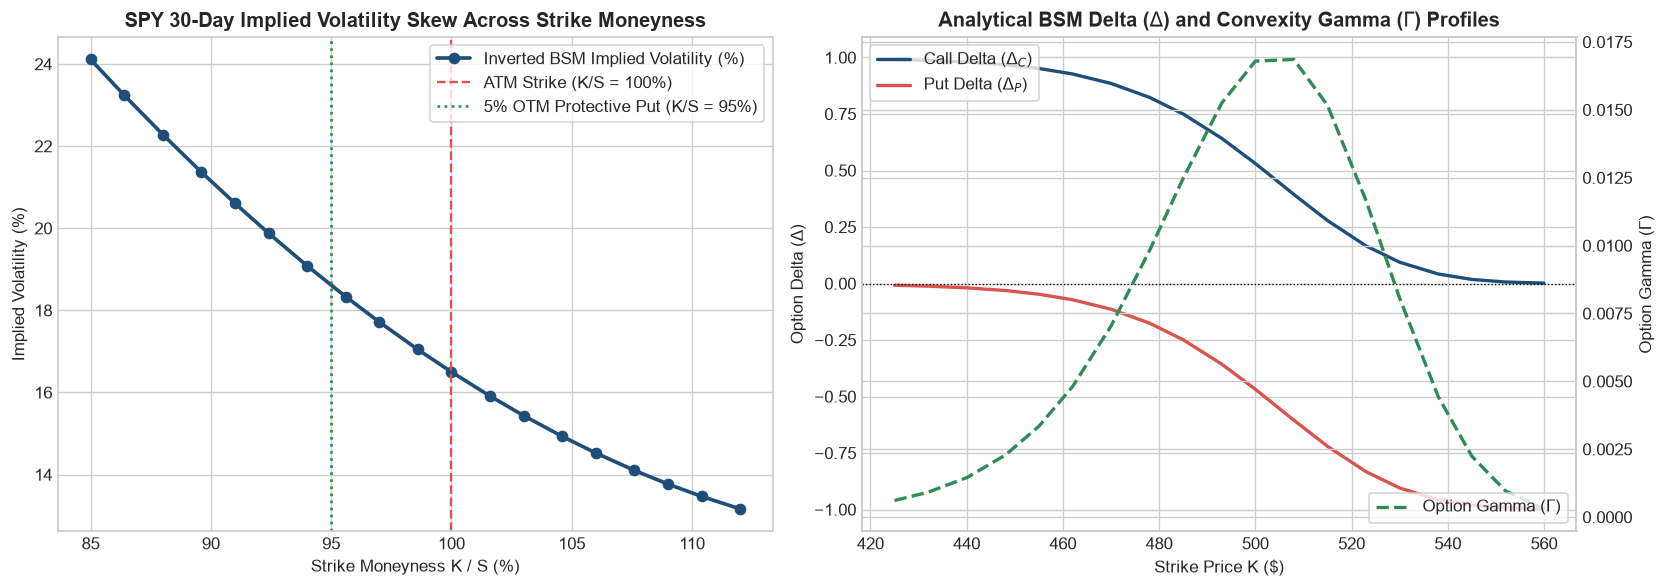

In [2]:
chain_df = generate_spy_option_chain_snapshot(spot_price=500.0, r=0.045, q=0.013, time_to_expiry_days=30, atm_iv=0.165)
puts_df = chain_df[chain_df["Option_Type"] == "PUT"]
calls_df = chain_df[chain_df["Option_Type"] == "CALL"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.0))
axes[0].plot(puts_df["Moneyness"] * 100.0, puts_df["Inverted_IV_pct"], "o-", color="#1f4e78", lw=2.2, label="Inverted BSM Implied Volatility (%)")
axes[0].axvline(100.0, color="#d9534f", ls="--", lw=1.4, label="ATM Strike (K/S = 100%)")
axes[0].axvline(95.0, color="#2e8b57", ls=":", lw=1.6, label="5% OTM Protective Put (K/S = 95%)")
axes[0].set_title("SPY 30-Day Implied Volatility Skew Across Strike Moneyness", fontweight="bold")
axes[0].set_xlabel("Strike Moneyness K / S (%)")
axes[0].set_ylabel("Implied Volatility (%)")
axes[0].legend(frameon=True)

ax2 = axes[1].twinx()
axes[1].plot(calls_df["Strike"], calls_df["Delta"], color="#1f4e78", lw=2.0, label="Call Delta ($\\Delta_C$)")
axes[1].plot(puts_df["Strike"], puts_df["Delta"], color="#d9534f", lw=2.0, label="Put Delta ($\\Delta_P$)")
ax2.plot(calls_df["Strike"], calls_df["Gamma"], color="#2e8b57", lw=2.0, ls="--", label="Option Gamma ($\\Gamma$)")
axes[1].axhline(0.0, color="black", lw=0.8, ls=":")
axes[1].set_title("Analytical BSM Delta ($\\Delta$) and Convexity Gamma ($\\Gamma$) Profiles", fontweight="bold")
axes[1].set_xlabel("Strike Price K ($)")
axes[1].set_ylabel("Option Delta ($\\Delta$)")
ax2.set_ylabel("Option Gamma ($\\Gamma$)")
axes[1].legend(loc="upper left", frameon=True)
ax2.legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()

## 2. Options & 5-Year Interest-Rate Swap VaR: Linear Delta/DV01 vs. Delta-Gamma-Vega vs. Full Revaluation MC

In [3]:
deriv_var_table, pnl_dists = compare_derivative_var_approaches(
    spot_price=500.0, spy_notional_usd=3_000_000.0, num_mc_scenarios=20_000, alpha=0.99
)
deriv_var_table[[
    "Portfolio_Structure", "Net_Delta_Shares", "Net_Gamma_Dollar", "Net_Vega_per_1pct_Vol",
    "Delta_Normal_VaR_99_USD", "Delta_Gamma_Vega_VaR_99_USD", "Full_Reval_MC_VaR_99_USD", "Full_Reval_MC_ES_99_USD", "Delta_Normal_Understatement_USD"
]].round(2)

,Portfolio_Structure,Net_Delta_Shares,Net_Gamma_Dollar,Net_Vega_per_1pct_Vol,Delta_Normal_VaR_99_USD,Delta_Gamma_Vega_VaR_99_USD,Full_Reval_MC_VaR_99_USD,Full_Reval_MC_ES_99_USD,Delta_Normal_Understatement_USD
0,"Long Delta-Neutral Straddle (6,000 sh)",0.00,2527.37,6855.06,0.00,20131.40,19320.09,21564.56,19320.09
1,"Short Delta-Neutral Straddle (-6,000 sh)",-0.00,-2527.37,-6855.06,0.00,34184.63,31305.43,38162.12,31305.43
2,Hedged $3M SPY + 5% OTM Protective Put,5095.63,654.23,2011.09,65198.20,58004.57,55893.34,62292.02,-9304.85
3,5Y $5M Pay-Fixed Interest-Rate Swap (IRS),2233.36,-0.58,0.00,40767.00,40961.14,40961.82,47097.31,194.82
4,Combined Derivatives Book (SPY Put + 5Y IRS),5095.63,52.34,2011.09,85849.18,79493.06,77447.44,87629.13,-8401.73


In [4]:
# 5-Year $5M Pay-Fixed Interest-Rate Swap: Linear DV01 vs Quadratic Convexity vs Exact Revaluation
swap_breakdown_df = evaluate_swap_approximation_breakdown(notional_usd=5_000_000.0)
swap_breakdown_df.round(2)

,Yield_Shock_bps,Linear_DV01_PnL_USD,Quadratic_DV01_Convexity_PnL_USD,Full_Revaluation_PnL_USD,Linear_DV01_Error_USD,Quadratic_Error_USD
0,-300.0,-670182.65,-722648.58,-725832.61,-55649.96,-3184.03
1,-200.0,-446788.43,-470106.63,-471034.84,-24246.41,-928.22
2,-100.0,-223394.22,-229223.77,-229337.94,-5943.72,-114.17
3,-50.0,-111697.11,-113154.50,-113168.65,-1471.54,-14.15
4,-25.0,-55848.55,-56212.90,-56214.66,-366.11,-1.76
5,25.0,55848.55,55484.21,55485.95,-362.60,1.75
6,50.0,111697.11,110239.72,110253.65,-1443.45,13.93
7,100.0,223394.22,217564.67,217675.30,-5718.92,110.63
8,200.0,446788.43,423470.24,424341.73,-22446.71,871.49
9,300.0,670182.65,617716.72,620613.30,-49569.35,2896.58


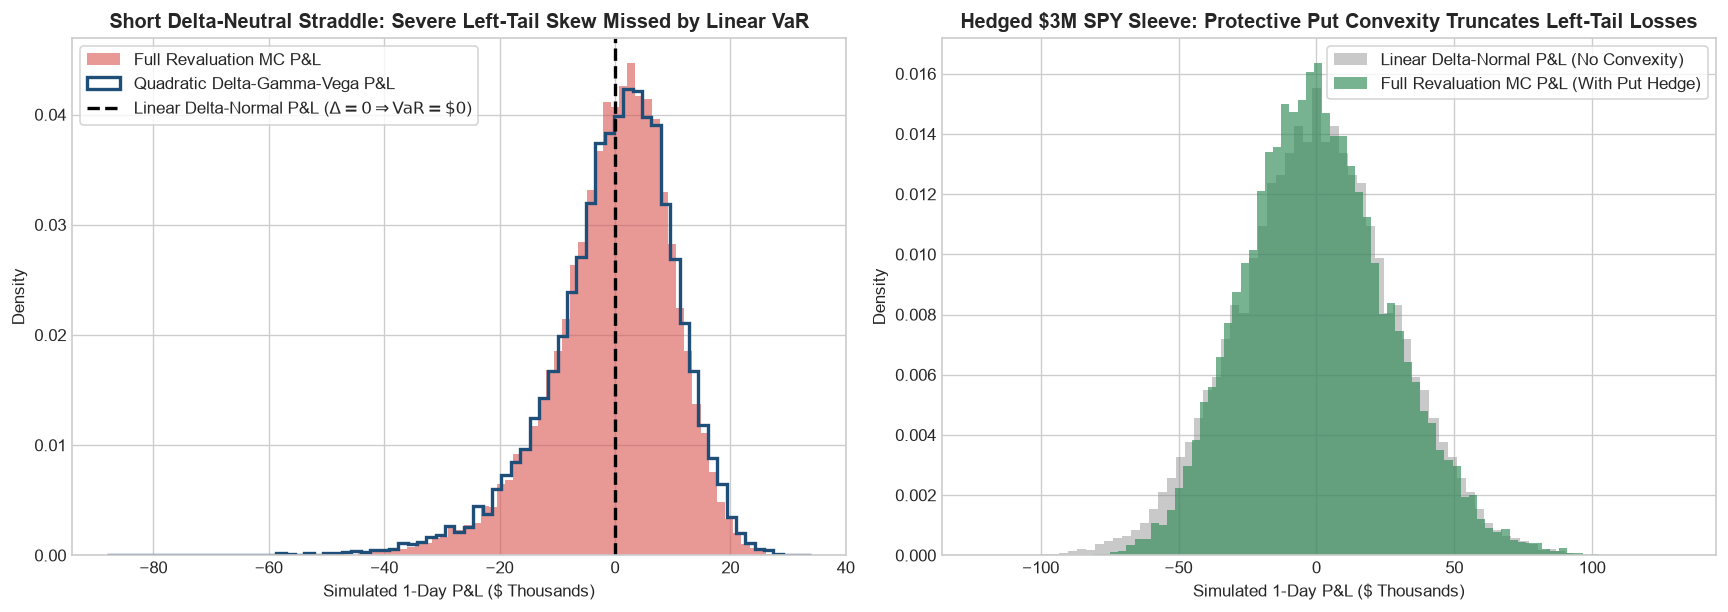

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

short_name = "Short Delta-Neutral Straddle (-6,000 sh)"
axes[0].hist(pnl_dists[f"{short_name} - Full Revaluation MC"] / 1e3, bins=75, density=True, alpha=0.60, color="#d9534f", label="Full Revaluation MC P&L")
axes[0].hist(pnl_dists[f"{short_name} - Delta-Gamma-Vega"] / 1e3, bins=75, density=True, histtype="step", lw=2.0, color="#1f4e78", label="Quadratic Delta-Gamma-Vega P&L")
axes[0].axvline(0.0, color="black", lw=2.0, ls="--", label="Linear Delta-Normal P&L ($\\Delta=0 \\Rightarrow \\text{VaR}=\\$0$)")
axes[0].set_title("Short Delta-Neutral Straddle: Severe Left-Tail Skew Missed by Linear VaR", fontweight="bold")
axes[0].set_xlabel("Simulated 1-Day P&L ($ Thousands)")
axes[0].set_ylabel("Density")
axes[0].legend(frameon=True)

hedged_name = "Hedged $3M SPY + 5% OTM Protective Put"
axes[1].hist(pnl_dists[f"{hedged_name} - Delta-Normal"] / 1e3, bins=75, density=True, alpha=0.45, color="#888888", label="Linear Delta-Normal P&L (No Convexity)")
axes[1].hist(pnl_dists[f"{hedged_name} - Full Revaluation MC"] / 1e3, bins=75, density=True, alpha=0.65, color="#2e8b57", label="Full Revaluation MC P&L (With Put Hedge)")
axes[1].set_title("Hedged $3M SPY Sleeve: Protective Put Convexity Truncates Left-Tail Losses", fontweight="bold")
axes[1].set_xlabel("Simulated 1-Day P&L ($ Thousands)")
axes[1].set_ylabel("Density")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

## 3. Basel 2.5 Stressed VaR ($\text{sVaR}_{0.99}$) vs. Normal-Period VaR & 2D Stress Grid

In [6]:
svar_df = compute_stressed_var_comparison(arith_returns, vix_df, weights=weights, notional_usd=notional_usd)
svar_df.round(2)

,Trading_Days,Mean_VIX,Ann_Portfolio_Vol_pct,Parametric_Normal_VaR_99_USD,Historical_Sim_VaR_99_USD,Historical_Sim_ES_99_USD,Stressed_to_Normal_VaR_Ratio
Regime_Window,,,,,,,
Normal Period (2017 Low-Vol Calm),253,11.36,5.66,80684.01,97075.31,115804.58,1.00
"Current Window (Latest 250d, 2025)",250,17.09,10.24,151353.73,158473.92,173658.09,1.63
Stressed Window A (2020 COVID-19 Crash),255,26.47,15.91,230331.08,338666.16,442361.32,3.49
Stressed Window B (2022 Rate-Hike Bear),253,22.86,16.82,251737.38,261257.27,287551.37,2.69


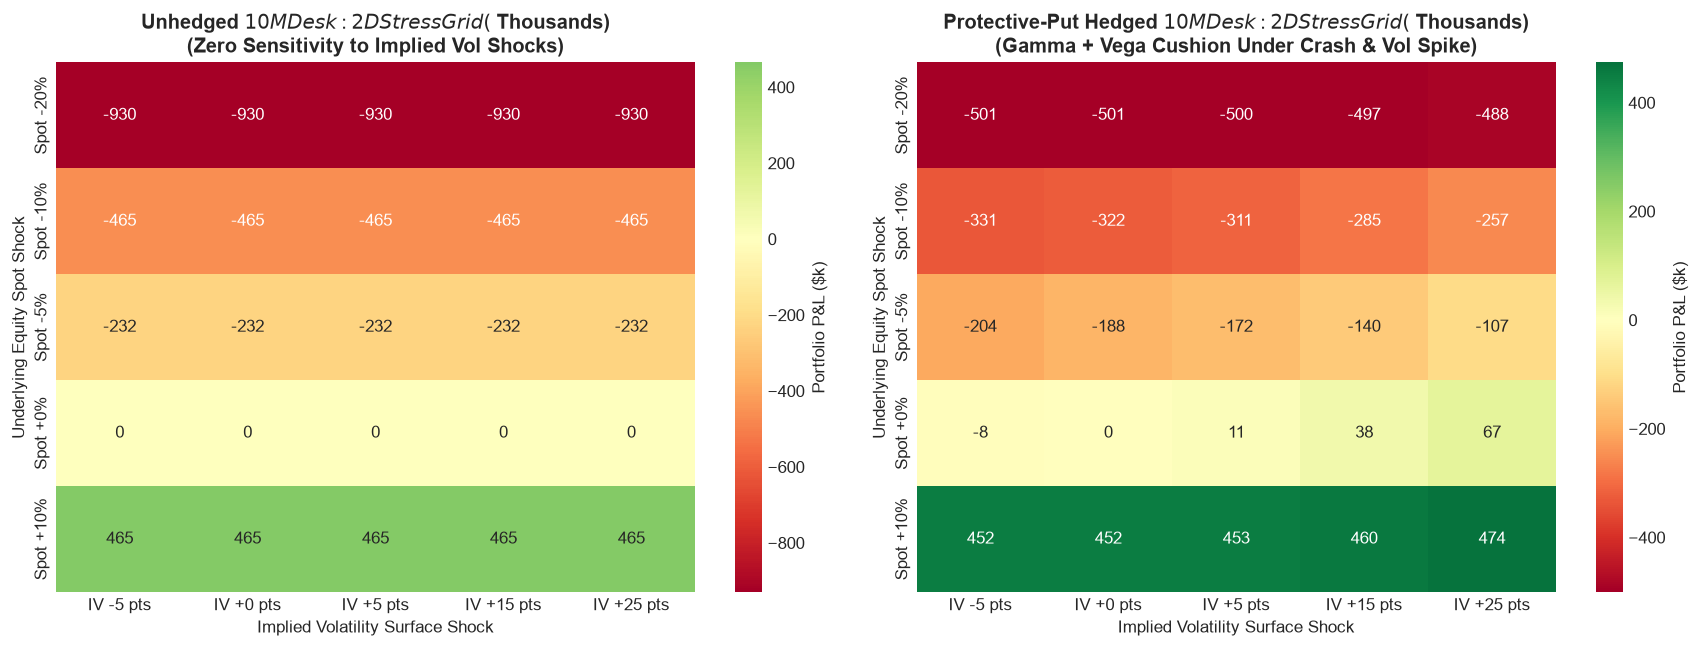

In [7]:
unhedged_grid, hedged_grid = build_2d_stress_vulnerability_grid(spot_price=500.0, spy_notional_usd=3_000_000.0)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))
sns.heatmap(unhedged_grid / 1e3, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "Portfolio P&L ($k)"}, ax=axes[0])
axes[0].set_title("Unhedged $10M Desk: 2D Stress Grid ($ Thousands)\n(Zero Sensitivity to Implied Vol Shocks)", fontweight="bold")
axes[0].set_ylabel("Underlying Equity Spot Shock")
axes[0].set_xlabel("Implied Volatility Surface Shock")

sns.heatmap(hedged_grid / 1e3, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "Portfolio P&L ($k)"}, ax=axes[1])
axes[1].set_title("Protective-Put Hedged $10M Desk: 2D Stress Grid ($ Thousands)\n(Gamma + Vega Cushion Under Crash & Vol Spike)", fontweight="bold")
axes[1].set_ylabel("Underlying Equity Spot Shock")
axes[1].set_xlabel("Implied Volatility Surface Shock")

plt.tight_layout()
plt.show()